<a href="https://colab.research.google.com/github/wUssopp/Eksploracja-Danych/blob/main/ED_braki_danych.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

,liczba braków,odsetek [%]
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


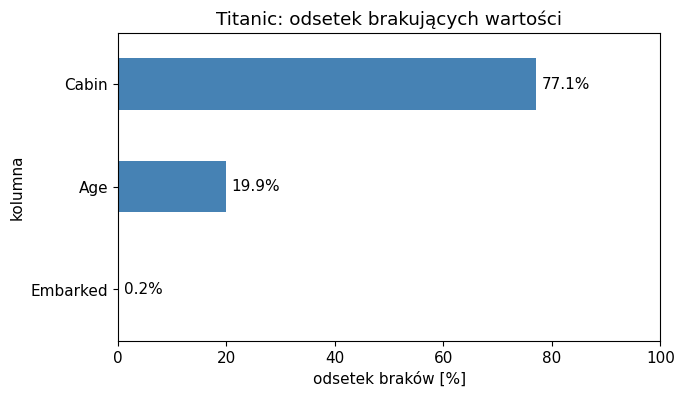

In [2]:
braki = titanic.isna()

tabela_brakow = pd.DataFrame({
    "liczba braków": braki.sum(),
    "odsetek [%]": (braki.mean() * 100).round(1),
})
tabela_brakow = (tabela_brakow[tabela_brakow["liczba braków"] > 0]
                 .sort_values("liczba braków", ascending=False))
display(tabela_brakow)

ax = tabela_brakow["odsetek [%]"].sort_values().plot.barh(color="steelblue")
ax.set_xlabel("odsetek braków [%]")
ax.set_ylabel("kolumna")
ax.set_title("Titanic: odsetek brakujących wartości")
for i, v in enumerate(tabela_brakow["odsetek [%]"].sort_values()):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, 100)
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

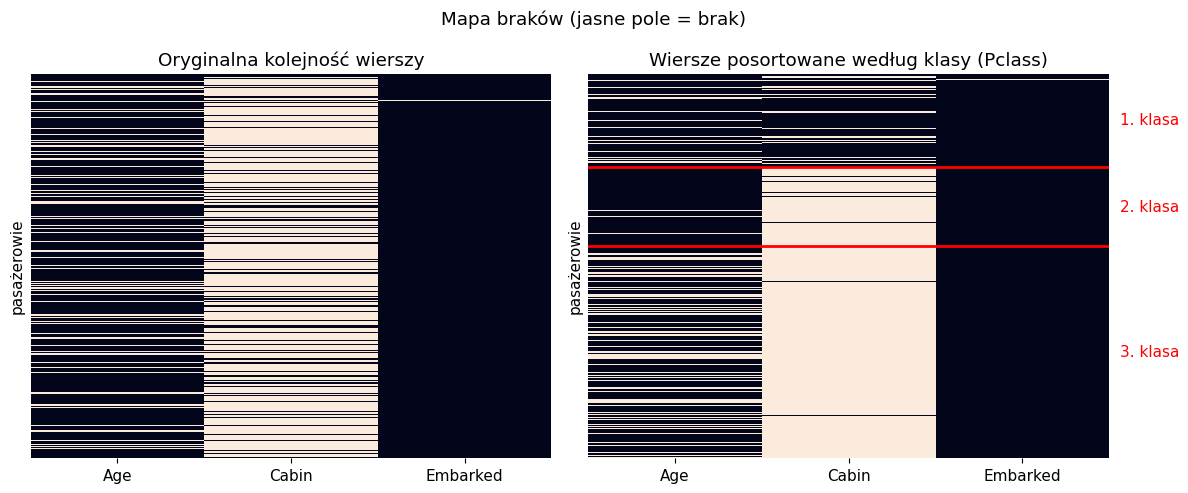

In [3]:
kolumny = ["Age", "Cabin", "Embarked"]

posortowane = titanic.sort_values("Pclass", kind="stable")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(titanic[kolumny].isna(), cbar=False, yticklabels=False, ax=axes[0])
axes[0].set_title("Oryginalna kolejność wierszy")

sns.heatmap(posortowane[kolumny].isna(), cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title("Wiersze posortowane według klasy (Pclass)")

liczebnosc = posortowane["Pclass"].value_counts().sort_index()
granice = liczebnosc.cumsum()
for g in granice.iloc[:-1]:
    axes[1].axhline(g, color="red", lw=2)
for klasa, koniec, n in zip(liczebnosc.index, granice, liczebnosc):
    axes[1].text(1.02, koniec - n / 2, f"{klasa}. klasa", ha="left", va="center",
                 transform=axes[1].get_yaxis_transform(), color="red")

for ax in axes:
    ax.set_ylabel("pasażerowie")
fig.suptitle("Mapa braków (jasne pole = brak)")
plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Na pierwszym wykresie braki wyglądają na przypadkowe. Dopiero po posortowaniu według klasy widać, od czego zależą. Numeru kabiny w 1. klasie brakuje rzadko (18,5%), a w 2. i 3. klasie prawie zawsze (91,3% i 97,6%), więc brak kabiny mówi coś o klasie pasażera. To MAR, a nie MCAR. Wieku też najczęściej brakuje w 3. klasie, tam jasnych pasków jest najwięcej. Oba braki w `Embarked` są w 1. klasie: to dwie pasażerki z tą samą kabiną B28 i biletem za 80 £.

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Odsetek braków wieku w klasach [%]:
 Pclass
1    13.9
2     6.0
3    27.7
Name: Age, dtype: float64 

Odsetek braków wieku według płci [%]:
 Sex
female    16.9
male      21.5
Name: Age, dtype: float64 

Odsetek ocalałych [%]:
 Age
wiek znany    40.6
brak wieku    29.4
Name: Survived, dtype: float64 



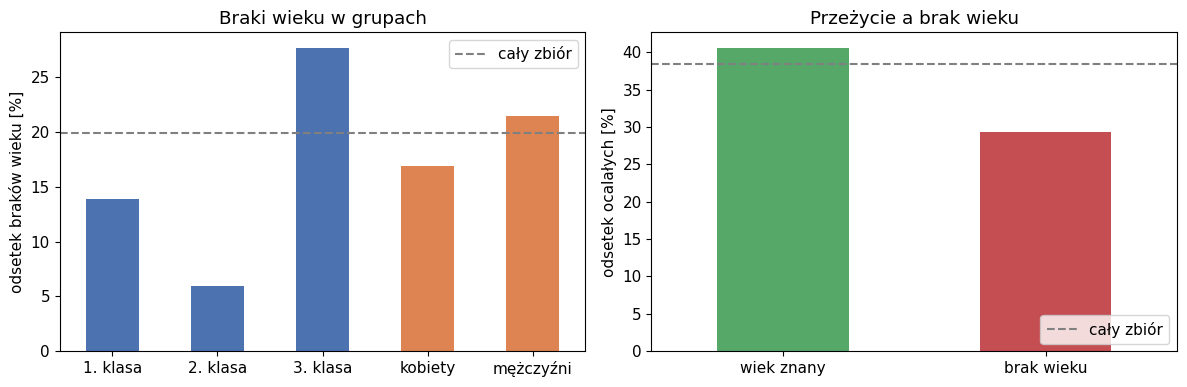

Odsetek ocalałych w całym zbiorze: 38.4%, po dropna(subset=['Age']): 40.6%


In [4]:
brak_wieku = titanic["Age"].isna()

braki_klasa = brak_wieku.groupby(titanic["Pclass"]).mean() * 100
braki_plec = brak_wieku.groupby(titanic["Sex"]).mean() * 100
print("Odsetek braków wieku w klasach [%]:\n", braki_klasa.round(1), "\n")
print("Odsetek braków wieku według płci [%]:\n", braki_plec.round(1), "\n")

przezycie = (titanic.groupby(brak_wieku)["Survived"].mean() * 100
             ).rename(index={False: "wiek znany", True: "brak wieku"})
print("Odsetek ocalałych [%]:\n", przezycie.round(1), "\n")

braki_grupy = pd.concat([
    braki_klasa.rename(index=lambda k: f"{k}. klasa"),
    braki_plec.rename(index={"female": "kobiety", "male": "mężczyźni"}),
])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
braki_grupy.plot.bar(ax=axes[0], color=["#4c72b0"] * 3 + ["#dd8452"] * 2, rot=0)
linia = axes[0].axhline(brak_wieku.mean() * 100, color="gray", ls="--", label="cały zbiór")
axes[0].set_ylabel("odsetek braków wieku [%]")
axes[0].set_title("Braki wieku w grupach")
axes[0].legend(handles=[linia])

przezycie.plot.bar(ax=axes[1], color=["#55a868", "#c44e52"], rot=0)
linia = axes[1].axhline(titanic["Survived"].mean() * 100, color="gray", ls="--", label="cały zbiór")
axes[1].set_xlabel("")
axes[1].set_ylabel("odsetek ocalałych [%]")
axes[1].set_title("Przeżycie a brak wieku")
axes[1].legend(handles=[linia], loc="lower right")
plt.tight_layout()
plt.show()

print(f"Odsetek ocalałych w całym zbiorze: {titanic['Survived'].mean():.1%}, "
      f"po dropna(subset=['Age']): {titanic.dropna(subset=['Age'])['Survived'].mean():.1%}")

*Twoja odpowiedź:* Braki wieku nie są MCAR. W 3. klasie wieku brakuje u 27,7% pasażerów, w 1. u 13,9%, a w 2. tylko u 6,0%, czyli w 3. klasie 4,6 raza częściej niż w 2. U mężczyzn braków jest trochę więcej niż u kobiet (21,5% i 16,9%). Przeżyło 40,6% osób ze znanym wiekiem i tylko 29,4% osób bez wieku.

Brak wieku zależy od klasy i płci, które znamy, więc to raczej MAR. Gdybym usunął wiersze bez wieku, wyrzuciłbym grupę, która częściej ginęła (głównie mężczyzn z 3. klasy), i odsetek ocalałych wzrósłby z 38,4% do 40,6%.

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [5]:
warianty = {
    "bez zmian": titanic,
    'dropna(subset=["Embarked"])': titanic.dropna(subset=["Embarked"]),
    'dropna(subset=["Age"])': titanic.dropna(subset=["Age"]),
    "dropna()": titanic.dropna(),
}

tabela_wariantow = pd.DataFrame({
    nazwa: {
        "liczba wierszy": len(df),
        "odsetek ocalałych [%]": round(df["Survived"].mean() * 100, 1),
        "odsetek 1. klasy [%]": round((df["Pclass"] == 1).mean() * 100, 1),
    }
    for nazwa, df in warianty.items()
}).T
tabela_wariantow["liczba wierszy"] = tabela_wariantow["liczba wierszy"].astype(int)
tabela_wariantow

,liczba wierszy,odsetek ocalałych [%],odsetek 1. klasy [%]
bez zmian,891,38.4,24.2
"dropna(subset=[""Embarked""])",889,38.2,24.1
"dropna(subset=[""Age""])",714,40.6,26.1
dropna(),183,67.2,86.3


*Twoja odpowiedź:* Usunięcie braków w `Embarked` zabiera tylko 2 wiersze i praktycznie nic nie zmienia (38,2% ocalałych, 24,1% z 1. klasy). Po `dropna(subset=["Age"])` znika 177 osób, odsetek ocalałych rośnie do 40,6%, a 1. klasy do 26,1%. To niewielkie, ale systematyczne przesunięcie, takie samo jak w zad. 3.

Najgorzej wypada `dropna()`. Zostaje 183 z 891 pasażerów, z czego 86,3% to 1. klasa (w całym zbiorze 24,2%), a odsetek ocalałych skacze z 38,4% do 67,2%. Winna jest kolumna `Cabin`: ma 77% braków, prawie wszystkie w 2. i 3. klasie, więc `dropna()` zostawia w zasadzie tylko pasażerów ze znaną kabiną, czyli zamożnych z 1. klasy, którzy częściej przeżyli. Taka próbka nie reprezentuje już pasażerów Titanica. Lepiej najpierw usunąć `Cabin` albo zamienić ją na flagę `ma_kabine`, a dopiero potem zajmować się resztą braków.

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

Mediany wieku w grupach (klasa × płeć):


Sex,female,male
Pclass,,
1,35.0,40.0
2,28.0,30.0
3,21.5,25.0


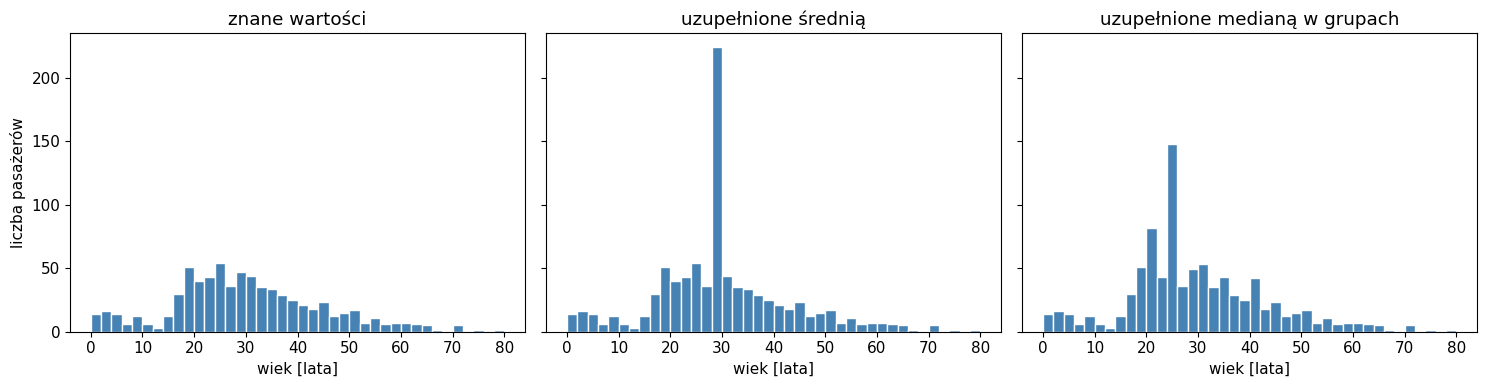

Odchylenie standardowe wieku:


,0
znane wartości,14.53
uzupełnione średnią,13.00
uzupełnione medianą w grupach,13.30


In [6]:
titanic["Age_brak"] = titanic["Age"].isna()

titanic["wiek_srednia"] = titanic["Age"].fillna(titanic["Age"].mean())

mediana_grupy = titanic.groupby(["Pclass", "Sex"])["Age"].transform("median")
titanic["wiek_grupy"] = titanic["Age"].fillna(mediana_grupy)

print("Mediany wieku w grupach (klasa × płeć):")
display(titanic.groupby(["Pclass", "Sex"])["Age"].median().unstack())

bins = np.arange(0, 82, 2)
wersje = [("Age", "znane wartości"),
          ("wiek_srednia", "uzupełnione średnią"),
          ("wiek_grupy", "uzupełnione medianą w grupach")]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (kol, tytul) in zip(axes, wersje):
    ax.hist(titanic[kol].dropna(), bins=bins, color="steelblue", edgecolor="white")
    ax.set_title(tytul)
    ax.set_xlabel("wiek [lata]")
axes[0].set_ylabel("liczba pasażerów")
plt.tight_layout()
plt.show()

odchylenia = titanic[["Age", "wiek_srednia", "wiek_grupy"]].std().round(2)
odchylenia.index = [t for _, t in wersje]
print("Odchylenie standardowe wieku:")
odchylenia

*Twoja odpowiedź:* Odchylenie standardowe znanych wartości to 14,53. Po uzupełnieniu średnią spada do 13,00, a po uzupełnieniu medianą w grupach do 13,30.

Bardziej zniekształca rozkład średnia. Każdy ze 177 braków dostaje 29,7 roku, więc na histogramie wyrasta jeden sztuczny słup z ponad 200 osobami. Mediana w grupach (klasa × płeć) wstawia 6 różnych wartości, od 21,5 do 40 lat. Słupów jest kilka i są niższe, a przy okazji zostają różnice między grupami, np. to, że w 3. klasie podróżowali młodsi ludzie. Obie metody i tak zaniżają zmienność, bo nie dodają żadnego rozrzutu. Dlatego zostawiam flagę `Age_brak`, żeby było wiadomo, które wartości są szacowane.

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

Przewidziany wiek poza zakresem przed przycięciem: 7 / 9


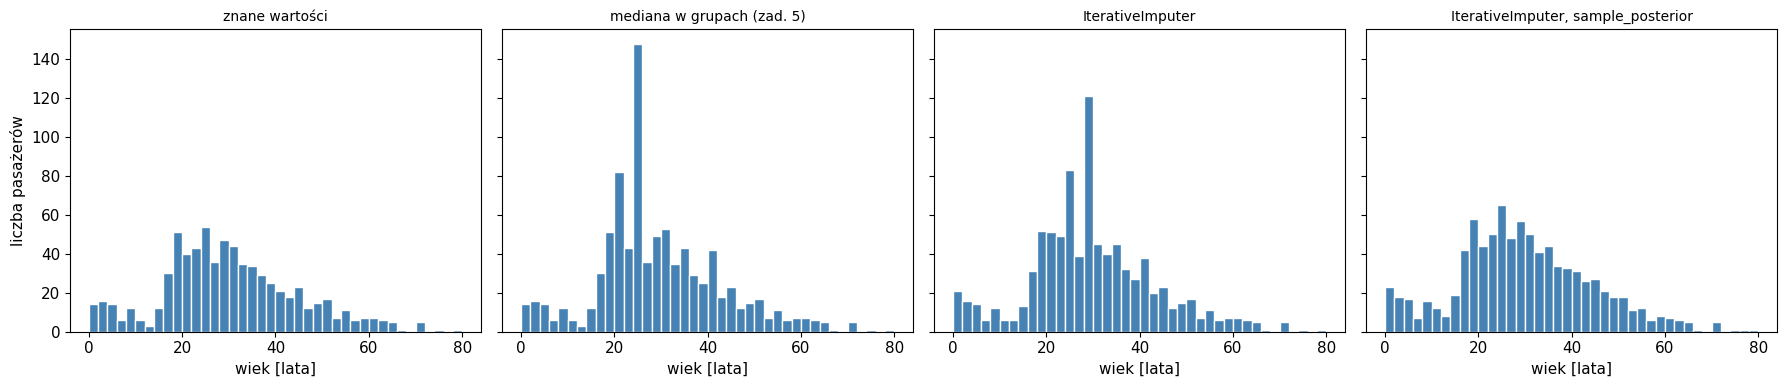

,odchylenie std.,średnia,korelacja z Pclass
Age,14.53,29.70,-0.37
wiek_grupy,13.30,29.11,-0.41
wiek_model,13.52,29.34,-0.40
wiek_model_los,14.52,29.37,-0.37
wiek_srednia,13.00,29.70,-0.33


In [7]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

X = titanic[["Age", "Pclass", "SibSp", "Parch", "Fare"]].copy()
X["Sex"] = (titanic["Sex"] == "female").astype(int)

imputer = IterativeImputer(random_state=0, max_iter=20)
wiek_model = imputer.fit_transform(X)[:, X.columns.get_loc("Age")]

imputer_los = IterativeImputer(random_state=0, max_iter=20, sample_posterior=True)
wiek_model_los = imputer_los.fit_transform(X)[:, X.columns.get_loc("Age")]

zakres = (titanic["Age"].min(), titanic["Age"].max())
print("Przewidziany wiek poza zakresem przed przycięciem:",
      ((wiek_model < zakres[0]) | (wiek_model > zakres[1])).sum(), "/",
      ((wiek_model_los < zakres[0]) | (wiek_model_los > zakres[1])).sum())
titanic["wiek_model"] = np.clip(wiek_model, *zakres)
titanic["wiek_model_los"] = np.clip(wiek_model_los, *zakres)

wersje6 = [("Age", "znane wartości"),
           ("wiek_grupy", "mediana w grupach (zad. 5)"),
           ("wiek_model", "IterativeImputer"),
           ("wiek_model_los", "IterativeImputer, sample_posterior")]

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (kol, tytul) in zip(axes, wersje6):
    ax.hist(titanic[kol].dropna(), bins=bins, color="steelblue", edgecolor="white")
    ax.set_title(tytul, fontsize=10)
    ax.set_xlabel("wiek [lata]")
axes[0].set_ylabel("liczba pasażerów")
plt.tight_layout()
plt.show()

porownanie_wieku = pd.DataFrame({
    "odchylenie std.": titanic[[k for k, _ in wersje6] + ["wiek_srednia"]].std(),
    "średnia": titanic[[k for k, _ in wersje6] + ["wiek_srednia"]].mean(),
    "korelacja z Pclass": titanic[[k for k, _ in wersje6] + ["wiek_srednia"]].corrwith(titanic["Pclass"]),
}).round(2)
porownanie_wieku

*Odpowiedź (zad. 6):* `IterativeImputer` przewiduje wiek z klasy, płci, liczby krewnych i ceny biletu, więc uzupełnione wartości różnią się między sobą, a nie są takie same w całej grupie. Na histogramie nadal jest górka w okolicach 28-30 lat, ale mniejsza niż przy średniej. Odchylenie standardowe wynosi 13,52, czyli trochę więcej niż przy medianie w grupach (13,30) i średniej (13,00). Model wstawia jednak najbardziej prawdopodobną wartość, więc też zaniża zmienność.

Dla 7 osób model przewidział ujemny wiek (od -4 do -7 lat). Wszystkie są z jednej rodziny z 3. klasy, która miała na pokładzie 8 rodzeństwa, i to duże `SibSp` ściąga przewidywanie w dół. Przyciąłem te wartości do najmniejszego znanego wieku (0,42 roku). Model nie wie, że wiek nie może być ujemny, więc takie rzeczy trzeba pilnować samemu.

Wariant z `sample_posterior=True` losuje wartość z rozkładu przewidywania, zamiast brać jego środek. Histogram wygląda wtedy prawie jak dla znanych danych, odchylenie wynosi 14,50 (w oryginale 14,53), a korelacja wieku z klasą zostaje na poziomie -0,37 (po średniej spada do -0,33). Minusem jest losowość i to, że pojedyncze wartości trafiają gorzej. Ten wariant ma sens, kiedy zależy mi na rozkładzie i zależnościach między zmiennymi, a nie na wieku konkretnego pasażera.

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [8]:
mieszkania = pd.read_csv("nieruchomosci.csv")

print("Typy kolumn:")
print(mieszkania.dtypes, "\n")

print("Braki widziane przez pandas:")
print(mieszkania.isna().sum())
print("Łącznie:", mieszkania.isna().sum().sum())

print("\nWartości w 'powierzchnia', które nie są liczbą:",
      mieszkania.loc[pd.to_numeric(mieszkania["powierzchnia"], errors="coerce").isna(),
                     "powierzchnia"].unique())

Typy kolumn:
id                int64
miasto           object
dzielnica        object
powierzchnia     object
liczba_pokoi      int64
rok_budowy       object
pietro           object
liczba_pieter     int64
parking          object
balkon           object
stan             object
cena_m2           int64
cena_total        int64
dtype: object 

Braki widziane przez pandas:
id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64
Łącznie: 8

Wartości w 'powierzchnia', które nie są liczbą: [nan 'brak']


*Twoja odpowiedź:* Bez dodatkowych parametrów pandas widzi tylko 8 braków: 4 w `powierzchnia` (zapisane jako `N/A`) i 4 w `rok_budowy` (zapisane jako `NA`). Oba napisy są na domyślnej liście braków w `read_csv`. Kolumny `powierzchnia`, `rok_budowy` i `pietro` wczytały się jako tekst (`str`), chociaż powinny być liczbowe.

W `powierzchnia` oprócz liczb jest napis `"brak"`. Wystarczy jedna wartość, której nie da się zamienić na liczbę, żeby pandas wczytał całą kolumnę jako tekst. Tak samo jest w `rok_budowy` i `pietro`. Z kolei `cena_m2` jest liczbowa, ale też ma ukryte braki (`-1` i `-999`), których pandas nie zauważył, bo to zwykłe liczby.

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [9]:
for kol in mieszkania.columns.drop(["id", "dzielnica"]):
    print(f"{kol:>14}: {mieszkania[kol].value_counts(dropna=False).to_dict()}")

print("\nWartości ≤ 0 w kolumnach liczbowych:")
print((mieszkania.select_dtypes("number").drop(columns="id") <= 0).sum())

print("\nMieszkania z piętrem 0:")
display(mieszkania.loc[mieszkania["pietro"] == "0",
                       ["id", "miasto", "powierzchnia", "pietro", "liczba_pieter", "cena_total"]])
print("Mieszkania z powierzchnią 0:")
display(mieszkania.loc[mieszkania["powierzchnia"] == "0",
                       ["id", "miasto", "powierzchnia", "liczba_pokoi", "cena_m2", "cena_total"]])

        miasto: {'Warszawa': 9, 'Kraków': 9, 'Wrocław': 9, 'Poznań': 9, 'Gdańsk': 9}
  powierzchnia: {nan: 4, '0': 3, '55': 2, '48': 2, '60': 2, '62': 2, '70': 2, '72': 2, '58': 2, 'brak': 2, '65': 1, '45': 1, '52': 1, '90': 1, '68': 1, '80': 1, '75': 1, '50': 1, '66': 1, '85': 1, '54': 1, '95': 1, '56': 1, '42': 1, '78': 1, '88': 1, '64': 1, '51': 1, '69': 1, '46': 1, '82': 1, '76': 1}
  liczba_pokoi: {3: 18, 2: 15, 4: 7, 1: 4, 5: 1}
    rok_budowy: {nan: 4, 'brak': 3, '2010': 2, '2018': 2, '2020': 2, '2015': 2, '2017': 2, '2019': 2, '2016': 2, '2014': 2, '2011': 2, '2013': 2, '2001': 1, '1998': 1, '2012': 1, '1995': 1, '2005': 1, '2008': 1, '1999': 1, '2003': 1, '2009': 1, '2021': 1, '1997': 1, '2007': 1, '2002': 1, '1996': 1, '2006': 1, '2022': 1, '2000': 1, '2004': 1}
        pietro: {'2': 9, '1': 8, '3': 7, '4': 6, '6': 3, '0': 3, '5': 3, '-999': 2, '7': 2, 'brak': 1, '8': 1}
 liczba_pieter: {4: 7, 5: 6, 8: 5, 10: 4, 9: 4, 6: 4, 7: 4, 3: 3, 11: 3, 12: 2, 2: 2, 15: 1}
       parkin

,id,miasto,powierzchnia,pietro,liczba_pieter,cena_total
6,7,Kraków,60,0,6,570000
17,18,Wrocław,brak,0,3,644000
33,34,Poznań,72,0,2,705600


Mieszkania z powierzchnią 0:


,id,miasto,powierzchnia,liczba_pokoi,cena_m2,cena_total
13,14,Poznań,0,2,10800,648000
28,29,Poznań,0,3,10200,612000
41,42,Kraków,0,2,9200,552000


*Twoja odpowiedź:* Wartości, które oznaczają brak:

| kolumna | oznaczenia braku |
|---|---|
| `powierzchnia` | `N/A` (4), `brak` (2), `0` (3) |
| `rok_budowy` | `NA` (4), `brak` (3) |
| `pietro` | `-999` (2), `brak` (1) |
| `parking` | `?` (5) |
| `balkon` | `?` (3) |
| `cena_m2` | `-1` (1), `-999` (1) |
| `stan` | brak braków, za to dziwna kategoria `很好` (zad. 9) |

Zero w tych dwóch kolumnach znaczy co innego. Powierzchnia 0 m² jest niemożliwa, a te trzy oferty mają po 2 lub 3 pokoje, normalną cenę za m² i cenę całkowitą 550-650 tys. zł, więc to brak danych. Piętro 0 to parter (tak jest w opisie kolumn), a mieszkania z piętrem 0 są w budynkach 2-, 3- i 6-piętrowych, więc nie ma tu nic podejrzanego. Dlatego `na_values` podaję jako słownik. Gdybym dał zwykłą listę z `"0"`, parter w `pietro` też zamieniłby się w NaN.

In [10]:
braki_slownik = {
    "powierzchnia": ["brak", "0", "N/A"],
    "rok_budowy": ["brak", "NA"],
    "pietro": ["brak", "-999"],
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": ["-1", "-999"],
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

print("Typy kolumn:")
print(mieszkania.dtypes, "\n")
print("Braki po poprawnym wczytaniu:")
print(mieszkania.isna().sum())
print("Łącznie:", mieszkania.isna().sum().sum())

Typy kolumn:
id                 int64
miasto            object
dzielnica         object
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking           object
balkon            object
stan              object
cena_m2          float64
cena_total         int64
dtype: object 

Braki po poprawnym wczytaniu:
id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          2
cena_total       0
dtype: int64
Łącznie: 29


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [11]:
print(mieszkania["stan"].value_counts(), "\n")

display(mieszkania.loc[mieszkania["stan"] == "很好"])
display(mieszkania.groupby("stan")["cena_m2"].agg(["mean", "median", "count"]).round(0))

print("Kraków, cena za m² według stanu:")
display(mieszkania[mieszkania["miasto"] == "Kraków"].groupby("stan")["cena_m2"].agg(["mean", "count"]).round(0))

mieszkania["stan"] = mieszkania["stan"].replace({"很好": "Bardzo dobry"})
mieszkania["stan"].value_counts()

stan
Dobry           28
Bardzo dobry    11
Do remontu       5
很好               1
Name: count, dtype: int64 



,id,miasto,dzielnica,powierzchnia,liczba_pokoi,rok_budowy,pietro,liczba_pieter,parking,balkon,stan,cena_m2,cena_total
1,2,Kraków,Krowodrza,48.0,2,NaN,2.0,5,Nie,Tak,很好,10200.0,489600


,mean,median,count
stan,,,
Bardzo dobry,11930.0,11750.0,10
Do remontu,8900.0,9000.0,5
Dobry,9837.0,9500.0,27
很好,10200.0,10200.0,1


Kraków, cena za m² według stanu:


,mean,count
stan,,
Bardzo dobry,9850.0,2
Do remontu,9000.0,1
Dobry,9360.0,5
很好,10200.0,1


,count
stan,
Dobry,28
Bardzo dobry,12
Do remontu,5


*Odpowiedź:* Wartość `很好` to po chińsku *hěn hǎo*, czyli „bardzo dobrze”. Reszta kategorii jest po polsku, więc pewnie ktoś wypełniał formularz w złej wersji językowej albo przepuścił tekst przez tłumacza. Zamieniam ją na `Bardzo dobry`, bo dokładnie to znaczy. Zgadza się też cena: 10 200 zł/m² to najwyższa cena wśród krakowskich ofert i bliżej jej do mieszkań w stanie bardzo dobrym (średnio 9 850) niż dobrym (9 360) czy do remontu (9 000).

Tej wartości nie zamieniam na NaN, bo wiadomo, co miała znaczyć. Poprawka przydaje się też w zad. 12: bez niej to mieszkanie byłoby jedynym w swojej grupie stanu, w dodatku bez znanego roku budowy, i mediana w grupie nie miałaby z czego go uzupełnić.

### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

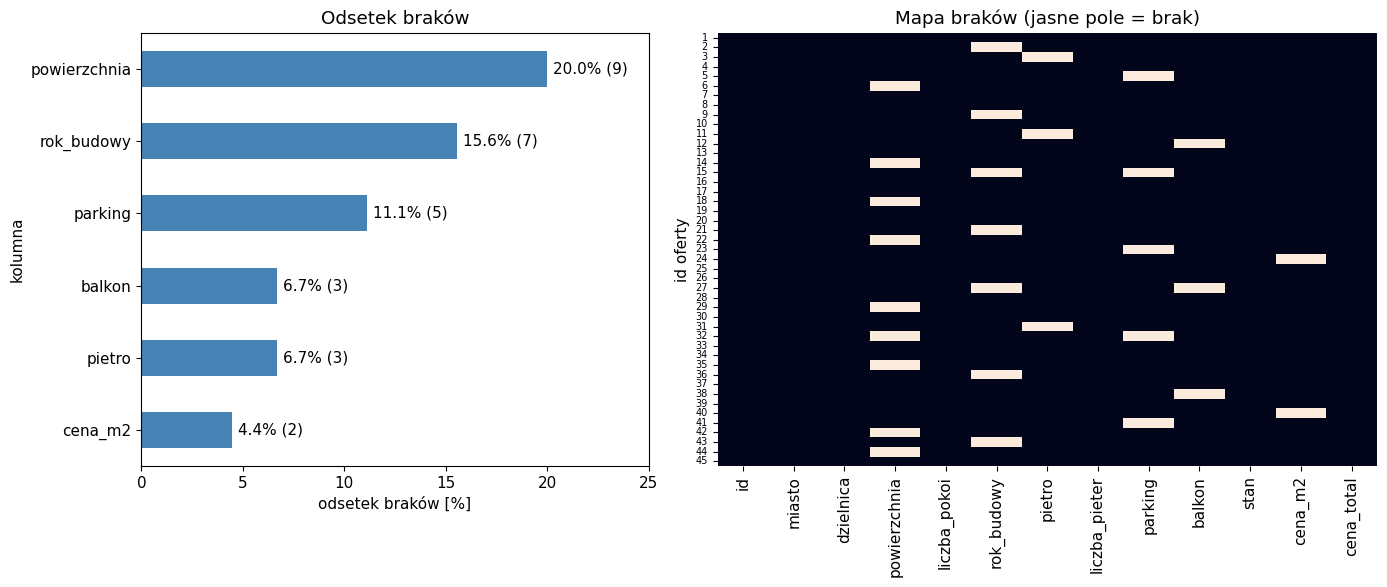

Korelacja wskaźników braku:


,powierzchnia,rok_budowy,pietro,parking,balkon,cena_m2
powierzchnia,1.00,-0.21,-0.13,-0.00,-0.13,-0.11
rok_budowy,-0.21,1.00,-0.11,0.04,0.13,-0.09
pietro,-0.13,-0.11,1.00,-0.09,-0.07,-0.06
parking,-0.00,0.04,-0.09,1.00,-0.09,-0.08
balkon,-0.13,0.13,-0.07,-0.09,1.00,-0.06
cena_m2,-0.11,-0.09,-0.06,-0.08,-0.06,1.00


Liczba braków w wierszu → ile takich wierszy:
0    19
1    23
2     3
Name: count, dtype: int64

Wiersze z brakiem jednocześnie w 'powierzchnia' i 'cena_m2': 0


In [12]:
braki_m = mieszkania.isna()
kol_z_brakami = braki_m.columns[braki_m.any()]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.3]})

odsetek = (braki_m[kol_z_brakami].mean() * 100).sort_values()
odsetek.plot.barh(ax=axes[0], color="steelblue")
axes[0].set_xlabel("odsetek braków [%]")
axes[0].set_ylabel("kolumna")
axes[0].set_title("Odsetek braków")
for i, v in enumerate(odsetek):
    axes[0].text(v + 0.3, i, f"{v:.1f}% ({round(v * len(mieszkania) / 100)})", va="center")
axes[0].set_xlim(0, 25)

sns.heatmap(braki_m, cbar=False, ax=axes[1], yticklabels=mieszkania["id"])
axes[1].set_title("Mapa braków (jasne pole = brak)")
axes[1].set_ylabel("id oferty")
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

print("Korelacja wskaźników braku:")
display(braki_m[kol_z_brakami].corr().round(2))

print("Liczba braków w wierszu → ile takich wierszy:")
print(braki_m.sum(axis=1).value_counts().sort_index())

print("\nWiersze z brakiem jednocześnie w 'powierzchnia' i 'cena_m2':",
      (braki_m["powierzchnia"] & braki_m["cena_m2"]).sum())

*Twoja odpowiedź:* Po poprawnym wczytaniu jest 29 braków w 6 kolumnach. Najwięcej w `powierzchnia` (9, czyli 20%), dalej `rok_budowy` (7), `parking` (5), `pietro` i `balkon` (po 3) oraz `cena_m2` (2).

Braki w różnych kolumnach raczej nie występują w tych samych wierszach. Korelacje między wskaźnikami braku są bliskie zera, od -0,21 do 0,13. Kompletnych wierszy jest 19, z jednym brakiem 23, a tylko 3 mają po dwa braki. Na mapie też nie widać żadnego wzoru i braki wyglądają na rozrzucone losowo, chociaż przy 45 wierszach trudno o mocne wnioski. Dla zad. 11 ważne jest to, że w żadnym wierszu nie brakuje jednocześnie `powierzchnia` i `cena_m2`, więc każdą z tych wartości da się policzyć z dwóch pozostałych.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [13]:
pelne = mieszkania.dropna(subset=["powierzchnia", "cena_m2"])
roznica = pelne["cena_total"] - pelne["powierzchnia"] * pelne["cena_m2"]
print(f"Sprawdzono {len(pelne)} wierszy; zależność zachodzi dokładnie w "
      f"{(roznica == 0).sum()} z nich (maks. |różnica| = {roznica.abs().max()} zł)\n")

braki_przed = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()
do_odtworzenia = mieszkania["powierzchnia"].isna() | mieszkania["cena_m2"].isna()

mieszkania["powierzchnia"] = mieszkania["powierzchnia"].fillna(
    mieszkania["cena_total"] / mieszkania["cena_m2"])
mieszkania["cena_m2"] = mieszkania["cena_m2"].fillna(
    (mieszkania["cena_total"] / mieszkania["powierzchnia"]).round(2))

braki_po = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()
display(pd.DataFrame({"przed": braki_przed, "po": braki_po, "usunięto": braki_przed - braki_po}))

print("Odtworzone wiersze:")
display(mieszkania.loc[do_odtworzenia, ["id", "miasto", "powierzchnia", "liczba_pokoi", "cena_m2", "cena_total"]])

Sprawdzono 34 wierszy; zależność zachodzi dokładnie w 34 z nich (maks. |różnica| = 0.0 zł)



,przed,po,usunięto
powierzchnia,9,0,9
cena_m2,2,0,2


Odtworzone wiersze:


,id,miasto,powierzchnia,liczba_pokoi,cena_m2,cena_total
5,6,Warszawa,80.0,2,15000.00,1200000
13,14,Poznań,60.0,2,10800.00,648000
17,18,Wrocław,70.0,4,9200.00,644000
21,22,Kraków,60.0,3,9800.00,588000
23,24,Poznań,48.0,1,12500.00,600000
28,29,Poznań,60.0,3,10200.00,612000
31,32,Kraków,60.0,2,9400.00,564000
34,35,Gdańsk,80.0,4,8800.00,704000
39,40,Gdańsk,82.0,4,8895.12,729400
41,42,Kraków,60.0,2,9200.00,552000


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [14]:
kolumny_do_uzupelnienia = ["rok_budowy", "pietro", "parking", "balkon"]

for kol in kolumny_do_uzupelnienia:
    mieszkania[f"{kol}_brak"] = mieszkania[kol].isna()
print("Liczba braków:", mieszkania[kolumny_do_uzupelnienia].isna().sum().to_dict(), "\n")

print(f"Mediana całościowa roku budowy: {mieszkania['rok_budowy'].median():.1f}")
statystyki = ["median", "std", "min", "max", "count"]
display(pd.concat({
    "wg miasta": mieszkania.groupby("miasto")["rok_budowy"].agg(statystyki),
    "wg stanu": mieszkania.groupby("stan")["rok_budowy"].agg(statystyki),
}).round(1))
print("Średnie odchylenie std. wewnątrz grup, miasto: "
      f"{mieszkania.groupby('miasto')['rok_budowy'].std().mean():.1f}, "
      f"stan: {mieszkania.groupby('stan')['rok_budowy'].std().mean():.1f} "
      f"(całość: {mieszkania['rok_budowy'].std():.1f})")

mediana_stan = mieszkania.groupby("stan")["rok_budowy"].transform("median")
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(mediana_stan).astype(int)
print("\nUzupełnione lata budowy:")
display(mieszkania.loc[mieszkania["rok_budowy_brak"], ["id", "miasto", "stan", "rok_budowy"]])

srodkowe = mieszkania["liczba_pieter"] // 2
display(mieszkania.loc[mieszkania["pietro_brak"], ["id", "liczba_pieter"]]
        .assign(mediana_calosciowa=mieszkania["pietro"].median(),
                srodkowe_pietro=srodkowe))
mieszkania["pietro"] = mieszkania["pietro"].fillna(srodkowe).astype(int)
assert (mieszkania["pietro"] <= mieszkania["liczba_pieter"]).all()

wiersze = {}
for kol in ["parking", "balkon"]:
    dominanta = mieszkania[kol].fillna(mieszkania[kol].mode()[0])
    nieznane = mieszkania[kol].fillna("nieznane")
    wiersze[kol] = {
        "dominanta": mieszkania[kol].mode()[0],
        "% 'Tak' wśród znanych": (mieszkania[kol].dropna() == "Tak").mean() * 100,
        "% 'Tak', wariant dominanta": (dominanta == "Tak").mean() * 100,
        "% 'Tak', wariant 'nieznane'": (nieznane == "Tak").mean() * 100,
    }
display(pd.DataFrame.from_dict(wiersze, orient="index").round(1))

for kol in ["parking", "balkon"]:
    mieszkania[kol] = mieszkania[kol].fillna("nieznane")
print(mieszkania["parking"].value_counts().to_dict(), mieszkania["balkon"].value_counts().to_dict())

print("\nLiczba braków w całym zbiorze:", mieszkania.isna().sum().sum())
assert mieszkania.isna().sum().sum() == 0

Liczba braków: {'rok_budowy': 7, 'pietro': 3, 'parking': 5, 'balkon': 3} 

Mediana całościowa roku budowy: 2011.5


median  std     min     max  count
wg miasta Gdańsk        2001.5  5.3  1997.0  2014.0      8
          Kraków        2013.0  8.4  1995.0  2019.0      7
          Poznań        2013.5  9.9  1996.0  2022.0      8
          Warszawa      2015.0  2.4  2013.0  2020.0      7
          Wrocław       2011.0  4.8  2006.0  2020.0      8
wg stanu  Bardzo dobry  2019.0  1.7  2017.0  2022.0     10
          Do remontu    1997.0  1.6  1995.0  1999.0      5
          Dobry         2010.0  5.0  2000.0  2016.0     23

Średnie odchylenie std. wewnątrz grup, miasto: 6.2, stan: 2.8 (całość: 7.8)

Uzupełnione lata budowy:


,id,miasto,stan,rok_budowy
1,2,Kraków,Bardzo dobry,2019
8,9,Poznań,Dobry,2010
14,15,Gdańsk,Dobry,2010
20,21,Warszawa,Bardzo dobry,2019
26,27,Kraków,Dobry,2010
35,36,Warszawa,Dobry,2010
42,43,Wrocław,Dobry,2010


,id,liczba_pieter,mediana_calosciowa,srodkowe_pietro
2,3,4,3.0,2
10,11,7,3.0,3
30,31,6,3.0,3


,dominanta,% 'Tak' wśród znanych,"% 'Tak', wariant dominanta","% 'Tak', wariant 'nieznane'"
parking,Tak,85.0,86.7,75.6
balkon,Tak,83.3,84.4,77.8


{'Tak': 34, 'Nie': 6, 'nieznane': 5} {'Tak': 35, 'Nie': 7, 'nieznane': 3}

Liczba braków w całym zbiorze: 0


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

powierzchnia       rok_budowy          cena_m2         
             przed    po      przed      po    przed       po
count         36.0  45.0       38.0    45.0     43.0     45.0
mean          64.6  64.9     2010.3  2010.6  10223.3  10244.3
std           13.7  12.8        7.8     7.4   1611.7   1623.9
min           42.0  42.0     1995.0  1995.0   8200.0   8200.0
25%           54.8  56.0     2004.2  2006.0   9000.0   9000.0
50%           63.0  62.0     2011.5  2011.0   9800.0   9800.0
75%           72.8  72.0     2016.8  2017.0  11100.0  11200.0
max           95.0  95.0     2022.0  2022.0  15000.0  15000.0

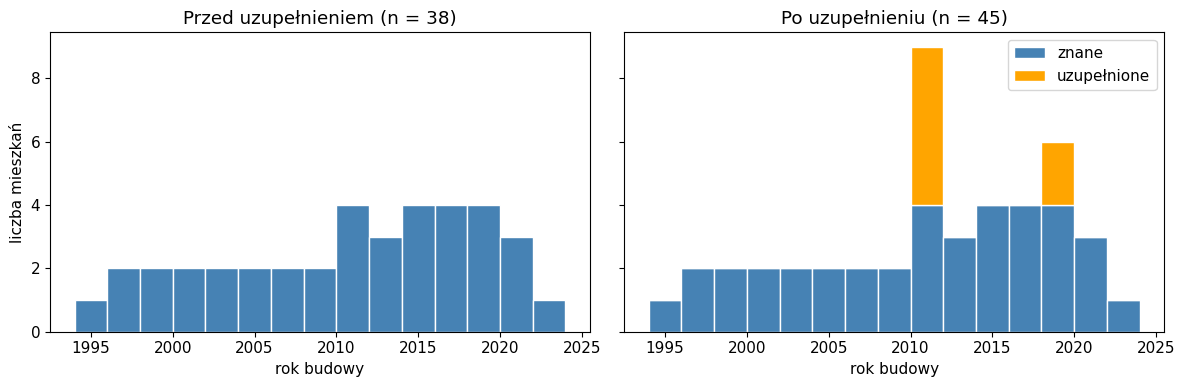

In [15]:
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
kolumny_opis = ["powierzchnia", "rok_budowy", "cena_m2"]

porownanie = pd.concat({"przed": surowe[kolumny_opis].describe(),
                        "po": mieszkania[kolumny_opis].describe()}, axis=1)
porownanie = porownanie.swaplevel(axis=1)[kolumny_opis].round(1)
display(porownanie)

przedzialy = np.arange(1994, 2025, 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].hist(surowe["rok_budowy"].dropna(), bins=przedzialy, color="steelblue", edgecolor="white")
axes[0].set_title(f"Przed uzupełnieniem (n = {surowe['rok_budowy'].notna().sum()})")

znane = mieszkania.loc[~mieszkania["rok_budowy_brak"], "rok_budowy"]
uzup = mieszkania.loc[mieszkania["rok_budowy_brak"], "rok_budowy"]
axes[1].hist([znane, uzup], bins=przedzialy, stacked=True, color=["steelblue", "orange"],
             edgecolor="white", label=["znane", "uzupełnione"])
axes[1].set_title(f"Po uzupełnieniu (n = {len(mieszkania)})")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("rok budowy")
axes[0].set_ylabel("liczba mieszkań")
plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Rozkłady nie zmieniły się w istotny sposób.

W `powierzchnia` i `cena_m2` średnia przesunęła się minimalnie (z 64,6 na 64,9 m² i z 10 223 na 10 244 zł/m²). Te wartości odtworzyłem dokładnie w zad. 11, więc zmiana bierze się z prawdziwych danych, a nie z szacowania.

W `rok_budowy` średnia prawie stoi w miejscu (z 2010,3 na 2010,6), mediana zmienia się z 2011,5 na 2011, a odchylenie standardowe spada lekko z 7,8 do 7,4. Na histogramie widać dwa małe słupki z uzupełnionych wartości: 5 mieszkań w 2010 i 2 w 2019. Mediana zawsze trochę zaniża zmienność, ale przy 7 brakach na 45 wierszy to niewielki efekt. Wstawione lata pasują przy tym do stanu mieszkania, np. mieszkania w bardzo dobrym stanie dostały 2019, a nie średni rok z całego zbioru.

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | `N/A`, `brak`, `0` | 9 (4 + 2 + 3) | odtworzenie z `cena_total / cena_m2` | wzór `cena_total = powierzchnia × cena_m2` zgadza się we wszystkich 34 kompletnych wierszach i nigdzie nie brakuje naraz powierzchni i ceny za m², więc znamy prawdziwą wartość; 0 m² jest niemożliwe |
| `cena_m2` | `-1`, `-999` | 2 | odtworzenie z `cena_total / powierzchnia` | jak wyżej, a ujemna cena jest niemożliwa; dla oferty nr 40 wychodzi 8 895,12 zł/m² (jedyna cena, która nie jest wielokrotnością 100) |
| `rok_budowy` | `NA`, `brak` | 7 (4 + 3) | flaga `rok_budowy_brak` i mediana w grupach według `stan` | rok mocno zależy od stanu (mediany: do remontu 1997, dobry 2010, bardzo dobry 2019), rozrzut w tych grupach jest mały (średnio 2,8 roku, przy podziale na miasta 6,2), a przy zakrywaniu znanych wartości ta metoda myli się najmniej (3,2 roku) |
| `pietro` | `-999`, `brak` | 3 (2 + 1) | flaga `pietro_brak` i środkowe piętro budynku (`liczba_pieter // 2`) | mediana (3) mogłaby nie pasować do niskiego budynku, a środkowe piętro zawsze w nim istnieje; `0` to parter, więc go nie ruszam |
| `parking` | `?` | 5 | flaga `parking_brak` i osobna kategoria `"nieznane"` | dominanta „Tak” zawyżyłaby odsetek mieszkań z parkingiem (z 85% do 86,7%); w ogłoszeniach brak informacji często znaczy brak parkingu, więc wolę nie zgadywać |
| `balkon` | `?` | 3 | flaga `balkon_brak` i osobna kategoria `"nieznane"` | dominanta zmieniłaby odsetek z 83,3% na 84,4%; „nieznane” zostawia niepewność i jest spójne z kolumną `parking` |
| `stan` | brak braków, za to błędna kategoria `很好` | 1 błędna wartość | zamiana `很好` na `Bardzo dobry` | `很好` to po chińsku „bardzo dobrze” (błąd przy wprowadzaniu albo tłumaczeniu), a cena za m² pasuje do stanu bardzo dobrego |

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [16]:
rok_z_brakami = mieszkania["rok_budowy"].where(~mieszkania["rok_budowy_brak"])

warianty_roku = {
    "bez braków (tylko znane)": rok_z_brakami,
    "mediana całościowa": rok_z_brakami.fillna(rok_z_brakami.median()),
    "mediana wg miasta": rok_z_brakami.fillna(rok_z_brakami.groupby(mieszkania["miasto"]).transform("median")),
    "mediana wg stanu": rok_z_brakami.fillna(rok_z_brakami.groupby(mieszkania["stan"]).transform("median")),
}

korelacje = pd.Series({nazwa: rok.corr(mieszkania["cena_m2"]) for nazwa, rok in warianty_roku.items()})
wynik = pd.DataFrame({
    "korelacja z cena_m2": korelacje,
    "zmiana względem danych bez braków": korelacje - korelacje.iloc[0],
}).round(3)
display(wynik)

display(pd.DataFrame({n: r[mieszkania["rok_budowy_brak"]] for n, r in list(warianty_roku.items())[1:]})
        .assign(id=mieszkania["id"], miasto=mieszkania["miasto"], stan=mieszkania["stan"],
                cena_m2=mieszkania["cena_m2"]).set_index("id"))

znane = mieszkania.loc[~mieszkania["rok_budowy_brak"]]
bledy = {}
for nazwa, grupa in [("mediana całościowa", None), ("mediana wg miasta", "miasto"), ("mediana wg stanu", "stan")]:
    prognozy = []
    for idx in znane.index:
        reszta = znane.drop(index=idx)
        if grupa is not None:
            reszta = reszta[reszta[grupa] == znane.at[idx, grupa]]
        prognozy.append(reszta["rok_budowy"].median())
    bledy[nazwa] = (znane["rok_budowy"] - pd.Series(prognozy, index=znane.index)).abs().mean()
print("Średni błąd bezwzględny przewidywania roku budowy (leave-one-out, lata):")
pd.Series(bledy).round(2)

,korelacja z cena_m2,zmiana względem danych bez braków
bez braków (tylko znane),0.709,0.000
mediana całościowa,0.678,-0.031
mediana wg miasta,0.710,0.001
mediana wg stanu,0.697,-0.011


,mediana całościowa,mediana wg miasta,mediana wg stanu,miasto,stan,cena_m2
id,,,,,,
2,2011.5,2013.0,2019.0,Kraków,Bardzo dobry,10200.0
9,2011.5,2013.5,2010.0,Poznań,Dobry,10500.0
15,2011.5,2001.5,2010.0,Gdańsk,Dobry,8700.0
21,2011.5,2015.0,2019.0,Warszawa,Bardzo dobry,12800.0
27,2011.5,2013.0,2010.0,Kraków,Dobry,9600.0
36,2011.5,2015.0,2010.0,Warszawa,Dobry,11200.0
43,2011.5,2011.0,2010.0,Wrocław,Dobry,10000.0


Średni błąd bezwzględny przewidywania roku budowy (leave-one-out, lata):


,0
mediana całościowa,7.00
mediana wg miasta,5.84
mediana wg stanu,3.21


*Twoja odpowiedź:* Na danych bez braków korelacja `rok_budowy` z `cena_m2` wynosi 0,709.

| wariant | korelacja | zmiana |
|---|---|---|
| mediana całościowa | 0,678 | -0,031 |
| mediana według miasta | 0,710 | +0,001 |
| mediana według stanu | 0,697 | -0,011 |

Korelację najmniej zmienia mediana według miasta. Najbardziej osłabia ją mediana całościowa, bo wszystkim 7 mieszkaniom wstawia ten sam rok 2011,5, bez względu na cenę. Dobrze to widać na mieszkaniu nr 21 z Warszawy za 12 800 zł/m²: mediana według miasta (2015) i według stanu (2019) pasują do wysokiej ceny, a całościowa nie.

Różnica między miastem a stanem jest jednak mała (0,012 przy 7 uzupełnionych wartościach), a zachowanie korelacji to tylko jedno kryterium. Sprawdziłem jeszcze, jak każda metoda trafia w pojedyncze wartości: po kolei zakrywałem każdy znany rok i przewidywałem go medianą jego grupy. Średni błąd dla stanu to 3,2 roku, dla miasta 5,8, a dla mediany całościowej 7,0. Dlatego w zad. 12 zostałem przy stanie. Wybór metody ma więc znaczenie, a który wariant jest lepszy, zależy od tego, czy ważniejsze są zależności między zmiennymi, czy trafność konkretnych wartości.